# Modeling spawning salmon

The plot below shows the relationship between the number of spawning salmon in a particular stream and the number of fry that are recruited into the population in the spring.

We would like to model this relationship, which appears to be non-linear (we have biological knowledge that suggests it should be non-linear too).

![](images/spawn.jpg)

In [3]:
import os

os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'

In [4]:
%matplotlib inline
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

import warnings
warnings.simplefilter('ignore')

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


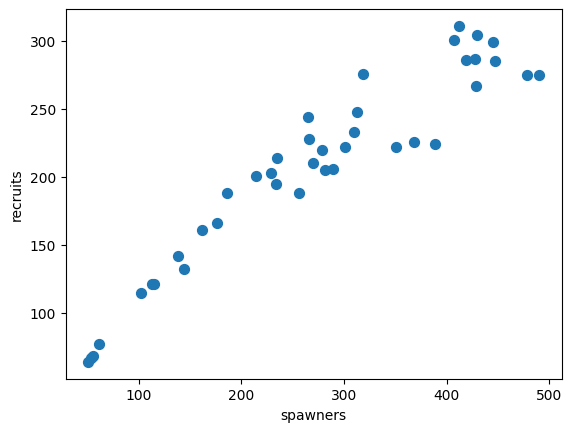

In [6]:
colab = True
if colab:
  salmon_data = pd.read_table("/content/drive/My Drive/Bayesian_programming/lesson4/data/salmon.txt", sep='\s+', index_col=0)
else:
  salmon_data = pd.read_table('./data/salmon.txt', sep='\s+', index_col=0)



salmon_data.plot.scatter(x='spawners', y='recruits', s=50);

# Parametric approaches

### Simple linear regression:

$$ y_i = \beta_0 + \beta_1 x_i + \epsilon_i $$

$$ \epsilon_i \sim N(0, \sigma) $$

### There are three unknowns, each of which need to be given a prior:

$$\beta_0, \beta_1 \sim \text{Normal}(0, 50)$$

$$\sigma \sim \text{HalfNormal}(50)$$

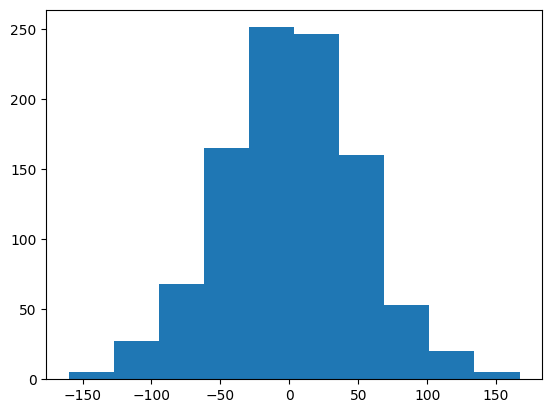

In [4]:
a_normal_distribution = pm.Normal.dist(mu=0, sigma=50)
plt.hist(pm.draw(a_normal_distribution, 1000));

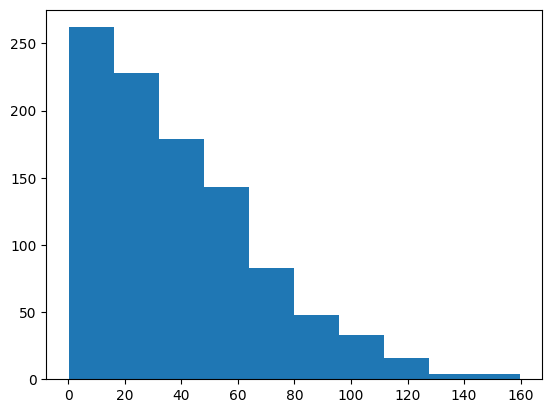

In [5]:
a_half_normal_distribution = pm.HalfNormal.dist(sigma=50)
plt.hist(pm.draw(a_half_normal_distribution, 1000));

Extract our predictor and response variables.

In [6]:
x, y = salmon_data[['spawners', 'recruits']].values.T

Construct a model in PyMC.

In [7]:
with pm.Model() as linear_salmon_model:

    β = pm.Normal('β', mu=0, sigma=50, shape=2)
    σ = pm.HalfNormal('σ', sigma=50)

    μ = β[0] + β[1] * x

    recruits = pm.Normal('recruits', mu=μ, sigma=σ, observed=y)

Fit the model using Markov chain Monte Carlo (MCMC).

In [8]:
with linear_salmon_model:

    linear_trace = pm.sample(2000, tune=500, cores=2)

Output()

Examine the posterior distributions of the unknown parameters.

Draw posterior samples of the regression line.

In [ ]:
linear_trace.posterior['β'][0,:10,:]

<xarray.DataArray 'β' (draw: 10, β_dim_0: 2)> Size: 160B
array([[62.53509999,  0.51681085],
       [67.36493204,  0.5008088 ],
       [73.26962806,  0.47741305],
       [64.3115286 ,  0.51692967],
       [58.7835848 ,  0.53596857],
       [63.35628586,  0.5291154 ],
       [63.7018141 ,  0.52467392],
       [63.64066586,  0.5242746 ],
       [68.02663765,  0.49014941],
       [83.03373289,  0.46726202]])
Coordinates:
    chain    int64 8B 0
  * draw     (draw) int64 80B 0 1 2 3 4 5 6 7 8 9
  * β_dim_0  (β_dim_0) int64 16B 0 1

In [ ]:
linear_trace.posterior['β'][1,:10,:]

<xarray.DataArray 'β' (draw: 10, β_dim_0: 2)>
array([[63.2436258 ,  0.51983045],
       [67.42174085,  0.52368948],
       [66.58227149,  0.51650873],
       [65.15541667,  0.51124464],
       [67.43136491,  0.51137615],
       [57.51475106,  0.52853394],
       [56.31651677,  0.5632614 ],
       [54.91917926,  0.56155075],
       [55.19381963,  0.56742989],
       [56.73404532,  0.56711965]])
Coordinates:
    chain    int64 1
  * draw     (draw) int64 0 1 2 3 4 5 6 7 8 9
  * β_dim_0  (β_dim_0) int64 0 1

In [5]:
X_pred = np.linspace(0, 500, 100)

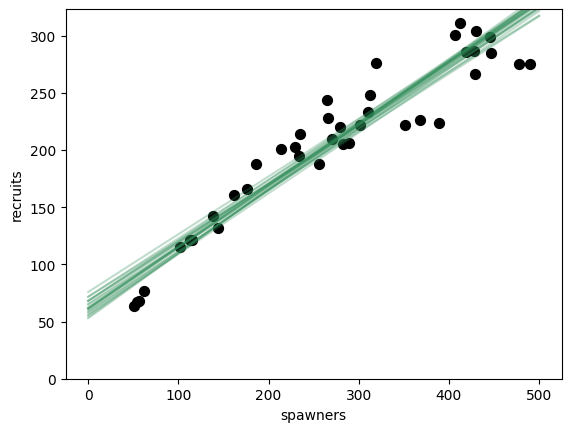

In [14]:


ax = salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50)
ax.set_ylim(0, None)
for ind in range(20):

    b0 = linear_trace.posterior['β'][0,ind, 0].item()
    b1 = linear_trace.posterior['β'][0,ind, 1].item()

    ax.plot(X_pred, b0 + b1*X_pred, alpha=0.3, color='seagreen');

### Quadratic Model

It appears the linear model is a poor fit to the data. Let's make a polynomial (quadratic) model by adding a parameter for $x^2$.

In [15]:
with pm.Model() as quad_salmon_model:

    β = pm.Normal('β', mu=0, sigma=50, shape=3)
    σ = pm.HalfNormal('σ', sigma=50)

    μ = β[0] + β[1] * x + β[2] * x**2

    recruits = pm.Normal('recruits', mu=μ, sigma=σ, observed=y)



In [12]:
with quad_salmon_model:

    quad_trace = pm.sample(2000, tune=500, cores=2, random_seed=1)

Output()

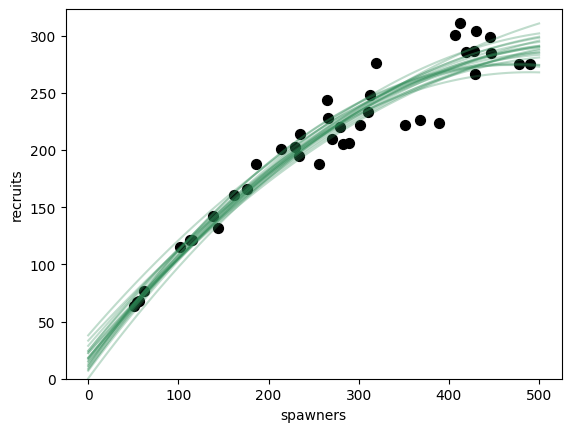

In [16]:
ax = salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50)
ax.set_ylim(0, None)

for ind in range(20):

    b0 = quad_trace.posterior['β'][0,ind, 0].item()
    b1 = quad_trace.posterior['β'][0,ind, 1].item()
    b2 = quad_trace.posterior['β'][0,ind, 2].item()

    ax.plot(X_pred, b0 + b1*X_pred + b2*X_pred**2, alpha=0.3, color='seagreen');

## Gaussian Process

In [7]:
with pm.Model() as gp_salmon_model:


    # priors on cov matrix parameters
    ρ = pm.HalfCauchy('ρ', 5)
    η = pm.HalfCauchy('η', 5)

    # Defining mean and covaraince
    M = pm.gp.mean.Linear(coeffs=(salmon_data.recruits/salmon_data.spawners).mean())
    K = (η**2) * pm.gp.cov.ExpQuad(1, ρ)

    # prior on noise
    σ = pm.HalfNormal('σ', 50)

    # Defining the GP prior
    recruit_gp = pm.gp.Marginal(mean_func=M, cov_func=K)

    # Likelihood, x and y should be inserted
    recruit_gp.marginal_likelihood('recruits', X=salmon_data.spawners.values.reshape(-1,1),
                           y=salmon_data.recruits.values, noise=σ)


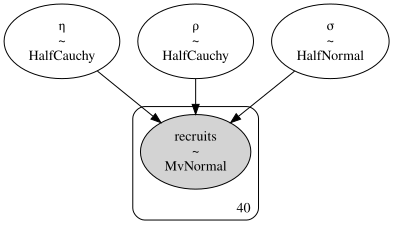

In [8]:
pm.model_to_graphviz(gp_salmon_model)

In [9]:
with gp_salmon_model:
    gp_trace = pm.sample(2000, tune=500, cores=2, random_seed=42)

Output()

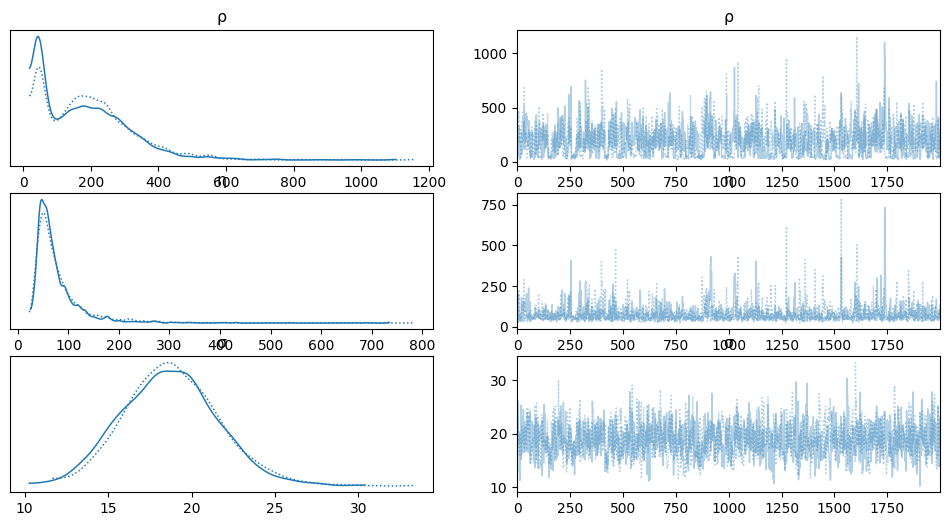

In [11]:
az.plot_trace(gp_trace, var_names=['ρ', 'η', 'σ']);

In [12]:
X_pred = np.linspace(0, 500, 100)
with gp_salmon_model:
    salmon_pred = recruit_gp.conditional("salmon_pred", X_pred.reshape(-1, 1))
    gp_salmon_samples = pm.sample_posterior_predictive(gp_trace, var_names=['salmon_pred'], random_seed=42)

Output()

## The posterior of Y can be printed in manually.

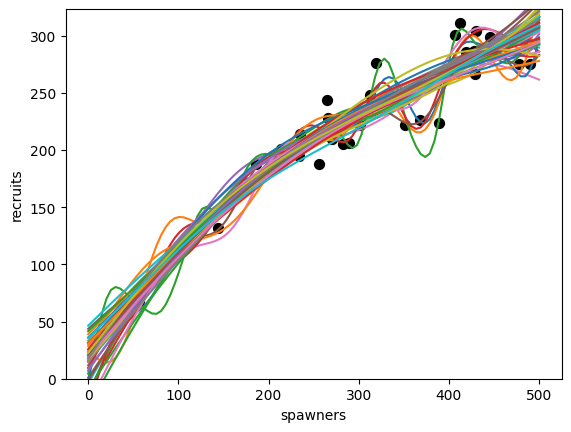

In [18]:
ax = salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50)
ax.set_ylim(0, None)

x = gp_salmon_samples.posterior_predictive['salmon_pred']

for ind in range(50):
    x = gp_salmon_samples.posterior_predictive['salmon_pred']
    ax.plot(X_pred, x[0,ind,:]);

## However, there is a designated function 'plot_gp_dist'.

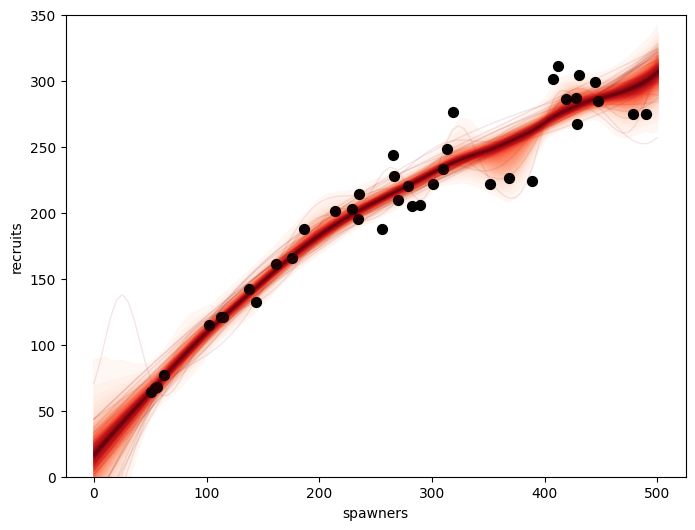

In [24]:
from pymc.gp.util import plot_gp_dist
fig, ax = plt.subplots(figsize=(8,6))
plot_gp_dist(ax, az.extract(gp_salmon_samples.posterior_predictive)['salmon_pred'].transpose(), X_pred)
salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50, ax=ax)
ax.set_ylim(0, 350);

## The figure above depicts the posterior without noise.
## The noise represent possible measurement error, or error in the data.
## If we wish to inlcude the noise in the posterior it looks like this:

In [25]:
with gp_salmon_model:
    salmon_pred_noise = recruit_gp.conditional("salmon_pred_noise", X_pred.reshape(-1,1), pred_noise=True)
    gp_salmon_samples = pm.sample_posterior_predictive(gp_trace, var_names=['salmon_pred_noise'], random_seed=42)

Output()

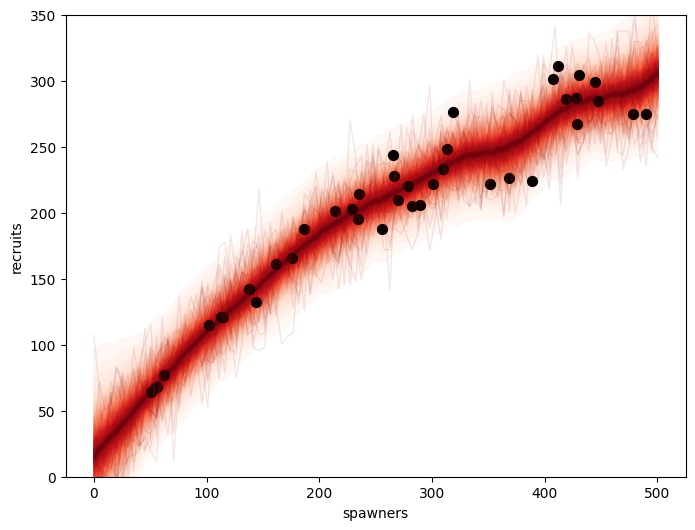

In [26]:
from pymc.gp.util import plot_gp_dist
fig, ax = plt.subplots(figsize=(8,6))

plot_gp_dist(ax, az.extract(gp_salmon_samples.posterior_predictive)['salmon_pred_noise'].transpose(), X_pred)
salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50, ax=ax)
ax.set_ylim(0, 350);


We might be interested in what may happen if the population gets very large -- say, 600 or 800 spawners. We can predict this, though it goes well outside the range of data that we have observed. Generate predictions from the posterior predictive distribution that covers this range of spawners.

*Hint: you need to add a new `conditional` variable.*

In [27]:
X_pred1 = np.linspace(0, 800, 150)

with gp_salmon_model:
    salmon_pred = recruit_gp.conditional("salmon_pred_extract", X_pred1.reshape(-1, 1))
    gp_salmon_samples = pm.sample_posterior_predictive(gp_trace, var_names=['salmon_pred_extract'],  random_seed=42)

Output()

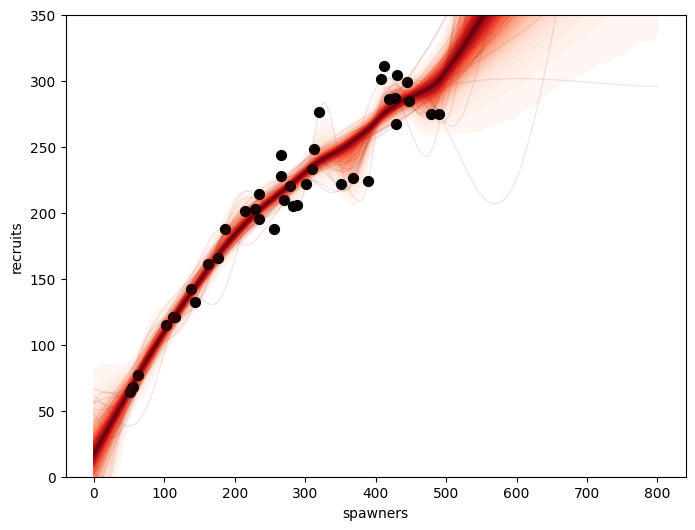

In [29]:
from pymc.gp.util import plot_gp_dist
fig, ax = plt.subplots(figsize=(8,6))

plot_gp_dist(ax, az.extract(gp_salmon_samples.posterior_predictive)['salmon_pred_extract'].transpose(), X_pred1)
salmon_data.plot.scatter(x='spawners', y='recruits', c='k', s=50, ax=ax)
ax.set_ylim(0, 350);

## Suppose we are really interested in what happens when the number of spawners are 300.
## We wish to know what is probability that three will be between 230 to 240 recruits?


In [19]:
with gp_salmon_model:
    salmon_pred_conditional = recruit_gp.conditional("salmon_pred_300", np.array([[300]]))
    gp_salmon_samples_conditional = pm.sample_posterior_predictive(gp_trace, var_names=['salmon_pred_300'], random_seed=42)

Output()

## Lets look at the distribution:

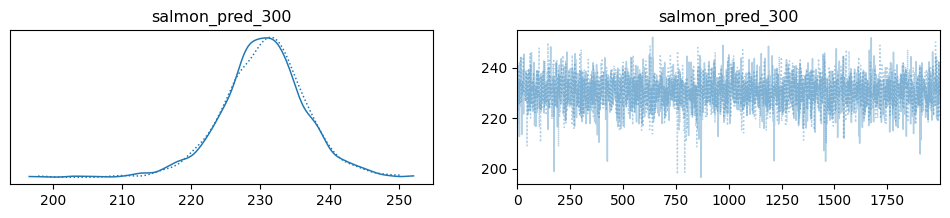

In [23]:
az.plot_trace(gp_salmon_samples_conditional.posterior_predictive, var_names=['salmon_pred_300']);

In [26]:
post_300_values = az.extract(gp_salmon_samples_conditional.posterior_predictive)['salmon_pred_300'].values.ravel()

In [28]:
((post_300_values>230)&(post_300_values<240)).mean()

np.float64(0.49625)

## Now lets compute the probability that there will be more recruits under 300 spawners against 310 spaweners?

In [42]:
with gp_salmon_model:
    salmon_pred_conditional = recruit_gp.conditional("salmon_pred_300_310", np.array([[300, 310]]))
    gp_salmon_samples_conditional = pm.sample_posterior_predictive(gp_trace, var_names=['salmon_pred_300_310'], random_seed=42)

Output()

In [43]:
vals_300_310 = az.extract(gp_salmon_samples_conditional.posterior_predictive)['salmon_pred_300_310'].values.transpose()

In [44]:
(vals_300_310[:,0]>vals_300_310[:,1]).mean()

np.float64(0.0)

## There is zero chance for this to happen